# Example: RMDC26_000566 — a blind Roman event with a spike next to the peak

The seventh blind example on simulated Roman data, after `example_rmdc26_000026` (a planetary caustic),
`example_rmdc26_001422` (a central caustic with a close/wide degeneracy), `example_rmdc26_001576` (a resonant
caustic), `example_rmdc26_001279` (a cusp approach at high magnification), `example_rmdc26_001532` (a double peak)
and `example_rmdc26_000209` (a planetary-caustic spike). Here a smooth high-magnification peak (magnification 43)
is followed six hours later by a sharp spike to 64, where the source passes the tip of a long, thin central caustic.

What it shows:

* **A central-caustic event where the angle screen works.** Unlike RMDC26_001279, the guided starts at the
  single-lens trajectory find both the close and the wide solution directly (6 minutes).
* **Valleys far thinner than the lattice.** The two minima are about 0.002 dex wide in log *s*. The coarse map
  grazes them at Δχ² = 175 and 440, an 8× zoom still at 13 and 18; only the 64× zooms resolve them. The close
  solution is preferred by Δχ² = 12.

**The data.** RMDC26_000566 is an event of the *Experienced tier* of the Roman Microlensing Data Challenge 2026
(RGES-PIT; public domain, CC0, [huggingface.co/datasets/RGES-PIT/Experienced](https://huggingface.co/datasets/RGES-PIT/Experienced)),
simulated with GULLS (Penny et al. 2019). The true parameters are not published, so this is a **blind** analysis.
The field is reddened (6.6, 2.7 and 0.9 mag of extinction in F087, F146 and F213): F087 is almost pure noise, and
F146 carries the event.

**Runtime.** On a 14-core Intel Core i5-13500 (20 threads): guided fits 6 minutes, coarse map 16 minutes, zooms
5 + 3 + 1 + 10 minutes, polish 2 minutes. Everything is stored in `data/`, so the notebook runs in a few seconds by
default; `RECOMPUTE = True` computes it all again (about an hour; the guided fits run serially there and take
longer).

## 0. Setup

In [1]:
import os, time, json
import numpy as np
import matplotlib.pyplot as plt
import lenscape
from lenscape import figures, caustics, model

RECOMPUTE = False              # True: compute all maps and fits again (a few hours on a 20-thread desktop)
LOGFILE = os.environ.get("LENSCAPE_LOG")          # progress of long runs is also appended here if set


def log(msg):
    print(msg, flush=True)
    if LOGFILE:
        with open(LOGFILE, "a") as f:
            f.write(f"{time.strftime('%H:%M:%S')} {msg}\n")

print("lenscape", lenscape.__version__)

lenscape 1.0


## 1. The photometry

`data/rmdc0566_photometry.csv`: all unsaturated points, with `set` (filter), `t` (BJD − 2460000) and `flux`,
`flux_err` in micro-Jansky as provided. Magnitudes below are AB, 23.9 − 2.5 log₁₀(flux / µJy).

In [2]:
SETS = ["F087", "F146", "F213"]
rows = np.genfromtxt("data/rmdc0566_photometry.csv", delimiter=",", names=True, dtype=None, encoding="utf-8",
                     skip_header=3)                     # the first three lines are comments
sel = lambda r, n: (r["t"][r["set"] == n], r["flux"][r["set"] == n], r["flux_err"][r["set"] == n])
data_all = lenscape.Data.from_sets({n: sel(rows, n) for n in SETS})
mag = lambda f: 23.9 - 2.5 * np.log10(f)                # AB magnitude of a flux in micro-Jansky
for n in SETS:
    t, f, e = sel(rows, n)
    print(f"{n}: {len(t)} points, median flux {np.median(f):9.4f} uJy, median error {np.median(e):.4f} uJy")

F087: 1501 points, median flux    0.1184 uJy, median error 0.2559 uJy
F146: 46488 points, median flux    6.5845 uJy, median error 0.1780 uJy
F213: 1499 points, median flux   84.7093 uJy, median error 0.8687 uJy


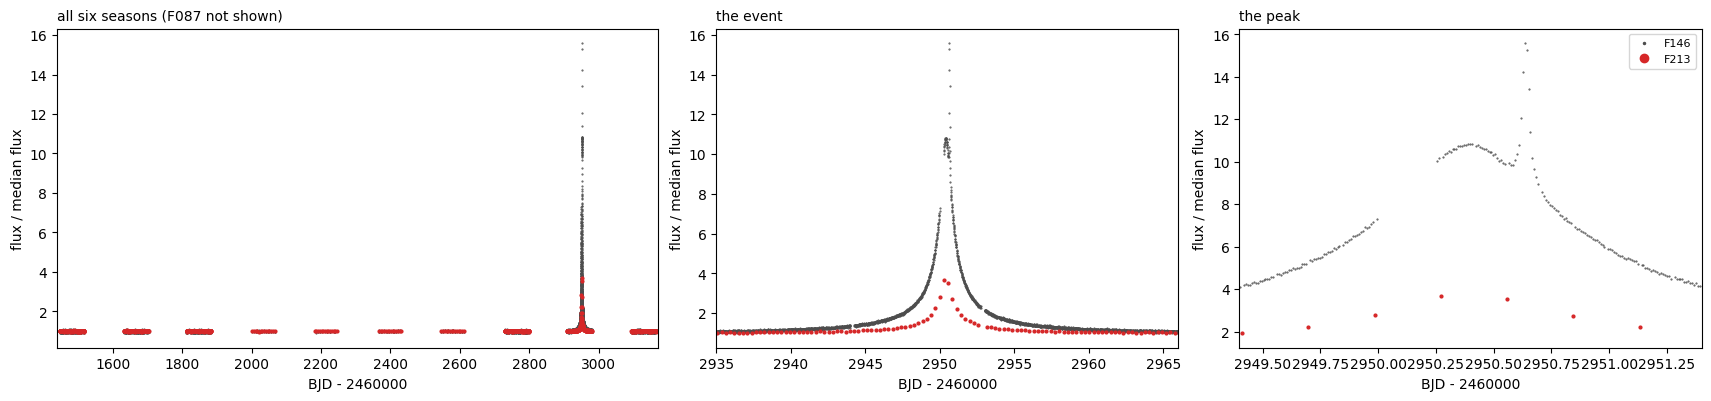

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(17, 3.9), gridspec_kw=dict(width_ratios=[1.3, 1, 1]), constrained_layout=True)
for ax, (a, b) in zip(axs, ((1440, 3170), (2935, 2966), (2949.4, 2951.4))):
    for n, c in (("F146", "0.3"), ("F213", "C3")):
        k = data_all.names.index(n)
        m = (data_all.idx == k) & (data_all.t > a) & (data_all.t < b)
        ax.plot(data_all.t[m], data_all.f[m] / np.median(data_all.f[data_all.idx == k]), ".", ms=1 if n == "F146" else 4,
                color=c, label=n, rasterized=True)
    ax.set_xlim(a, b); ax.set_xlabel("BJD - 2460000"); ax.set_ylabel("flux / median flux")
axs[0].set_title("all six seasons (F087 not shown)", loc="left", fontsize=10)
axs[1].set_title("the event", loc="left", fontsize=10)
axs[2].set_title("the peak", loc="left", fontsize=10); axs[2].legend(fontsize=8, markerscale=3)

The event is in the seventh season. The flux rises by a factor of 11 at the peak (BJD′ = 2950.4, BJD′ = BJD −
2460000), smoothly for about two weeks around it. The right panel shows the peak: a broad hump, a short dip and
a sharp spike at BJD′ 2950.63, all within about half a day. F146 has a gap of six hours just before the hump's
maximum (BJD′ 2950.0–2950.25). F087 is not plotted; with 6.6 mag of extinction its points scatter by more than the
baseline flux. It is kept in the fits, where it weighs little.

## 2. Reducing the data for the maps

The same reduction as in the other examples: the event season only (BJD′ 2909–2979), F146 at full cadence over
the peak (BJD′ 2949.6–2951.3), in 1-hour bins within 8 days of the peak (*t*₀ = 2950.4) and 3-hour bins elsewhere;
F087 and F213 unbinned.

In [4]:
SEASON = (2909.0, 2979.0)
ANOM = (2949.6, 2951.3)
T0_BIN, TE_BIN = 2950.4, 8.0
def reduce(rows):
    # season only; F146: full cadence in ANOM, 1-h bins within TE_BIN of T0_BIN, 3-h bins elsewhere
    out = {}
    for n in SETS:
        t, f, e = sel(rows, n)
        m = (t >= SEASON[0]) & (t <= SEASON[1])
        t, f, e = t[m], f[m], e[m]
        if n != "F146":
            out[n] = (t, f, e); continue
        full = (t >= ANOM[0]) & (t <= ANOM[1])
        inner = np.abs(t - T0_BIN) < TE_BIN
        key = np.floor((t - SEASON[0]) / np.where(inner, 1 / 24, 3 / 24)).astype(int) * 2 + inner
        b = ~full
        u, inv = np.unique(key[b], return_inverse=True)
        w = 1 / e[b] ** 2
        W = np.bincount(inv, w)
        T, F, E = (np.r_[t[full], np.bincount(inv, w * t[b]) / W], np.r_[f[full], np.bincount(inv, w * f[b]) / W],
                   np.r_[e[full], W ** -0.5])
        o = np.argsort(T)
        out[n] = (T[o], F[o], E[o])
    return lenscape.Data.from_sets(out)

data = reduce(rows)
season = data_all.window(*SEASON)
be = lenscape.make_backend(lenscape.config.REFINE_BACKEND)
print(f"all {len(data_all)} points, season {len(season)}, binned {len(data)}:",
      {n: len(s) for n, s in zip(data.names, data.slices)})

all 49488 points, season 8096, binned 1397: {'F087': 239, 'F146': 919, 'F213': 239}


## 3. The single lens and what the peak says

A point lens with a finite source, fitted with the peak masked, gives *t*₀ = 2950.41, *u*₀ ≈ 0.04 and *t*ₑ ≈ 15 d.
The anomaly sits *at* the peak, when the source is closest to the host: it comes from the **central caustic**, the
small caustic at the host that every planet produces. A planet at separation *s* and one at 1/*s* produce nearly
the same central caustic (Griest & Safizadeh 1998; Dominik 1999), so a close and a wide solution are expected.

## 4. Guided fits

At log *s* = ±0.05, ±0.1, ±0.2, ±0.3, ±0.5 and ±0.8, every log *q* from −5 to 0 (steps of 0.5) and three source sizes,
360 trajectory angles are tried at the single-lens trajectory (143 000 trial light curves, 31 s on 20 cores). The 24
best distinct starts are fitted in all seven parameters (`lenscape.fit_full`), then the offset-degenerate partner
(`lenscape.fit.offset_partner`) of the 8 best results. The fits were run in parallel (6 minutes); the stored results
are loaded here (`RECOMPUTE = True` runs them again, serially).

In [5]:
first_file = "data/rmdc0566_first_fits.json"
if RECOMPUTE or not os.path.exists(first_file):
    log("computing the guided fits")
    from scipy.optimize import minimize
    m = data.select(~((data.t >= ANOM[0]) & (data.t <= ANOM[1])))
    def c2_single(x):
        A = lenscape.single.lc_1l1s(x[0], x[1], abs(x[2]) + 1e-3, 10 ** min(x[3], -0.5), m.t, 0.0)
        return model.chi2_profiled(A, m.f, m.w, m.idx, m.nsets)
    r = min((minimize(c2_single, [2950.4, u0, tE, -2.5], method="Nelder-Mead", options=dict(maxfev=4000, adaptive=True))
             for u0 in (0.02, 0.05, 0.1) for tE in (5.0, 10.0, 20.0)), key=lambda r: r.fun)
    sl = dict(t0=float(r.x[0]), u0=abs(float(r.x[1])), tE=abs(float(r.x[2])) + 1e-3)
    grid = lenscape.make_backend(lenscape.config.GRID_BACKEND)
    trials = []
    for ls in [v * sg for v in (0.05, 0.1, 0.2, 0.3, 0.5, 0.8) for sg in (1, -1)]:
        for lq in np.arange(-5.0, 0.01, 0.5):
            for lr in (-3.0, -2.5, -2.0):
                for a in np.arange(360) * 2 * np.pi / 360:
                    p = [sl["t0"], sl["u0"], sl["tE"], ls, float(lq), float(a), lr]
                    trials.append((model.chi2(grid, p, data), p))
    trials.sort(key=lambda r: r[0])
    def distinct(rows, n, ds, dq, da):
        out = []
        for c, p in rows:
            if all(abs(p[3] - q[3]) > ds or abs(p[4] - q[4]) > dq or abs(np.angle(np.exp(1j * (p[5] - q[5])))) > da
                   for _, q in out):
                out.append((c, p))
            if len(out) == n:
                break
        return out
    def full_fit(p):
        c, p = lenscape.fit_full(data, p, grid, rounds=2, maxfev=3000)
        c, p = lenscape.fit_full(data, p, be, rounds=2, maxfev=3000)
        return float(c), [float(v) for v in p]
    res = sorted((full_fit(p) for _, p in distinct(trials, 24, 0.01, 0.1, 0.15)), key=lambda r: r[0])
    res += [full_fit(lenscape.fit.offset_partner(np.array(p)).tolist()) for _, p in distinct(res, 8, 0.005, 0.05, 0.1)]
    json.dump(dict(single_lens=sl, fits=sorted(res, key=lambda r: r[0])), open(first_file, "w"), indent=1)
first = json.load(open(first_file))
sl = first["single_lens"]
print(f"single lens (peak masked): t0 = {sl['t0']:.3f}, u0 = {sl['u0']:.4f}, tE = {sl['tE']:.2f} d")
print(f"{'chi2':>9s} {'log s':>8s} {'log q':>7s} {'alpha':>6s} {'u0':>8s} {'tE':>7s} {'log rho':>7s}")
shown = []
for c, p in first["fits"]:
    if all(abs(p[3] - q[3]) > 0.003 or abs(p[4] - q[4]) > 0.03 for _, q in shown):
        shown.append((c, p))
        print(f"{c:9.2f} {p[3]:+8.4f} {p[4]:+7.3f} {p[5] % (2 * np.pi):6.3f} {p[1]:+8.5f} {p[2]:7.3f} {p[6]:+7.3f}")
    if len(shown) == 12:
        break
best_first = np.array(first["fits"][0][1])
wide_first = np.array([p for c, p in first["fits"] if p[3] > 0][0])

single lens (peak masked): t0 = 2950.409, u0 = 0.0385, tE = 15.05 d
     chi2    log s   log q  alpha       u0      tE log rho
  1392.80  -0.0672  -3.265  4.137 -0.02229  15.295  -3.038
  1404.04  +0.0793  -3.260  4.138 -0.02220  15.260  -3.038
 36291.32  -0.0114  -3.432  4.703 +0.01891  17.471  -1.992
 41887.57  -0.6499  -0.991  4.040 +0.02044  16.454  -5.000
 41993.68  +0.6997  -0.930  4.029 +0.41129  17.710  -5.000
 41997.41  +0.6934  -0.940  4.033 +0.39819  17.553  -4.996
 42005.66  +0.6825  -0.967  4.039 +0.37000  17.622  -5.000
 42020.82  +0.6756  -0.972  4.043 +0.36219  17.246  -4.153
 42033.57  +0.6632  -1.012  4.051 +0.32608  17.642  -4.878
 42065.67  +0.6485  -1.047  4.060 +0.29590  17.649  -4.858
 45548.00  +0.0874  -2.920  4.453 +0.02233  16.848  -1.760
 46221.82  +0.2313  -2.577  4.694 +0.01821  20.009  -5.000


Two fits stand out, as expected: **close** (log *s* = −0.067, χ² = 1392.8 for 1397 binned points) and **wide**
(log *s* = +0.079, 11 higher), both with log *q* = −3.26. Everything else is worse by 35 000 or more; the single
lens with the peak by 185 000.

The binning is checked as in the other examples: the Δχ² between the two is the same on the binned data, the
unbinned season and all six seasons.

In [6]:
check = {"close": best_first, "wide": wide_first}
c = {k: [model.chi2(be, p, d) for d in (data, season, data_all)] for k, p in check.items()}
print(f"{'':7s} {'binned':>10s} {'season':>10s} {'all':>10s}   (Delta chi2 to the close fit)")
for k, v in c.items():
    print(f"{k:7s} " + " ".join(f"{a - b:10.2f}" for a, b in zip(v, c["close"])))
print(f"close fit: chi2 = {c['close'][0]:.1f} (binned, N = {len(data)}), {c['close'][1]:.1f} (season, N = {len(season)}), "
      f"{c['close'][2]:.1f} (all, N = {len(data_all)})")

            binned     season        all   (Delta chi2 to the close fit)
close         0.00       0.00       0.00
wide         11.24      11.30      12.39
close fit: chi2 = 1392.8 (binned, N = 1397), 8410.4 (season, N = 8096), 49651.8 (all, N = 49488)


## 5. The coarse map

The same lattice as before: −1 ≤ log *s* ≤ 1 in steps of 0.04, −5 ≤ log *q* ≤ 0 in steps of 0.1, 51 × 51
points, no refinement more than 500 above the minimum. **Runtime: 16 minutes.**

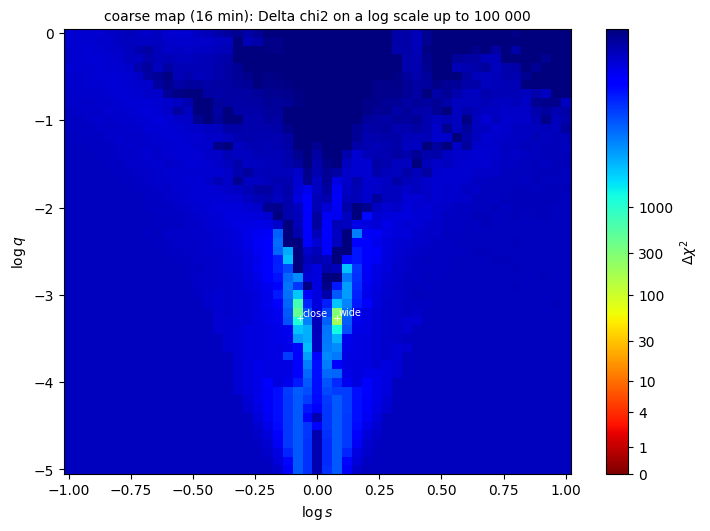

In [7]:
KEYS = ("logs", "logq", "chi2", "pars", "chi2_ref", "wall")


def run_or_load(name, compute):
    # data/rmdc0566_map_NAME.npz: computed (and saved) if missing or RECOMPUTE, else loaded
    path = f"data/rmdc0566_map_{name}.npz"
    if RECOMPUTE or not os.path.exists(path):
        log(f"computing map {name}")
        m = compute()
        np.savez_compressed(path, **{k: m[k] for k in KEYS})
        log(f"map {name}: {m['chi2'].shape}, {m['wall'] / 60:.1f} min, lowest chi2 {np.nanmin(m['chi2']):.2f}")
        return m
    return dict(np.load(path))

logs1 = np.round(np.arange(-1.0, 1.0001, 0.04), 4)
logq1 = np.round(np.arange(-5.0, 0.0001, 0.1), 4)
map1 = run_or_load("1x", lambda: lenscape.lattice(data, logs1, logq1, best=best_first, bin_wings=False, dchi2_cut=5.0,
                                                  log=log))
ref0 = first["fits"][0][0]
fig, ax = plt.subplots(figsize=(7, 5.2), constrained_layout=True)
figures.plot_map(map1, ax=ax, vmax=100000, chi2_ref=ref0, marks={"close": best_first[3:5], "wide": wide_first[3:5]})
ax.set_title(f"coarse map ({map1['wall'] / 60:.0f} min): Delta chi2 on a log scale up to 100 000", fontsize=10);

The map is the V of central-caustic events, as for RMDC26_001422 and RMDC26_001279: the highest values (darkest)
fill a V that opens towards large *q* (a heavy companion near the Einstein ring makes a central caustic far too
large), and below log *q* ≈ −2 the lower values gather in a band around log *s* = 0. Inside it, two thin columns
at log *s* ≈ ±0.08 reach
down to a few hundred: the lattice columns next to the two solutions. Their lowest points are 175 (log *s* = +0.08,
wide side) and 440 (log *s* = −0.08, close side) above the guided fit. The valleys are much narrower than the
lattice step of 0.04 in log *s*, so the coarse map shows where they are but not how deep.

## 6. Zooming into the two valleys

`lenscape.maps.densify` refines boxes aligned with the coarse lattice: 8× in log *s* and 4× in log *q*
(0.005 × 0.025) around both columns, then 64× × 16× (0.000625 × 0.00625) around each minimum.

In [8]:
step = lambda lo, hi, x0, st: np.round(x0 + st * np.arange(int(np.ceil((lo - x0) / st - 1e-9)),
                                                           int(np.floor((hi - x0) / st + 1e-9)) + 1), 6)
dens = lambda prev, s, q, fs, fq: lenscape.maps.densify(prev, data, step(*s, -1.0, 0.04 / fs), step(*q, -5.0, 0.1 / fq),
                                                         best=best_first, bin_wings=False, log=log)
mapc8 = run_or_load("close_8x", lambda: dens([map1], (-0.12, -0.04), (-3.8, -2.8), 8, 4))
mapw8 = run_or_load("wide_8x", lambda: dens([map1], (0.04, 0.12), (-3.8, -2.8), 8, 4))
mapc64 = run_or_load("close_64x", lambda: dens([mapc8, map1], (-0.080, -0.055), (-3.35, -3.20), 64, 16))
mapw64 = run_or_load("wide_64x", lambda: dens([mapw8, map1], (0.070, 0.090), (-3.35, -3.15), 64, 16))
MAPS = [("coarse", map1), ("close 8x", mapc8), ("wide 8x", mapw8), ("close 64x", mapc64), ("wide 64x", mapw64)]
ref = min(np.nanmin(m["chi2"]) for _, m in MAPS)
for name, m in MAPS:
    i, j = np.unravel_index(np.nanargmin(m["chi2"]), m["chi2"].shape)
    print(f"{name:10s}: {m['chi2'].shape[0]:2d} x {m['chi2'].shape[1]:2d} points, {m['wall'] / 60:4.1f} min, lowest point "
          f"{m['chi2'][i, j] - ref:7.2f} at log s = {m['logs'][i]:+.6f}, log q = {m['logq'][j]:.5f}")

coarse    : 51 x 51 points, 16.1 min, lowest point  174.89 at log s = +0.080000, log q = -3.30000
close 8x  : 17 x 41 points,  5.0 min, lowest point   17.82 at log s = -0.065000, log q = -3.27500
wide 8x   : 17 x 41 points,  3.4 min, lowest point   13.19 at log s = +0.080000, log q = -3.25000
close 64x : 41 x 25 points,  1.4 min, lowest point    0.00 at log s = -0.066875, log q = -3.26875
wide 64x  : 33 x 33 points,  9.5 min, lowest point   11.19 at log s = +0.079375, log q = -3.26250


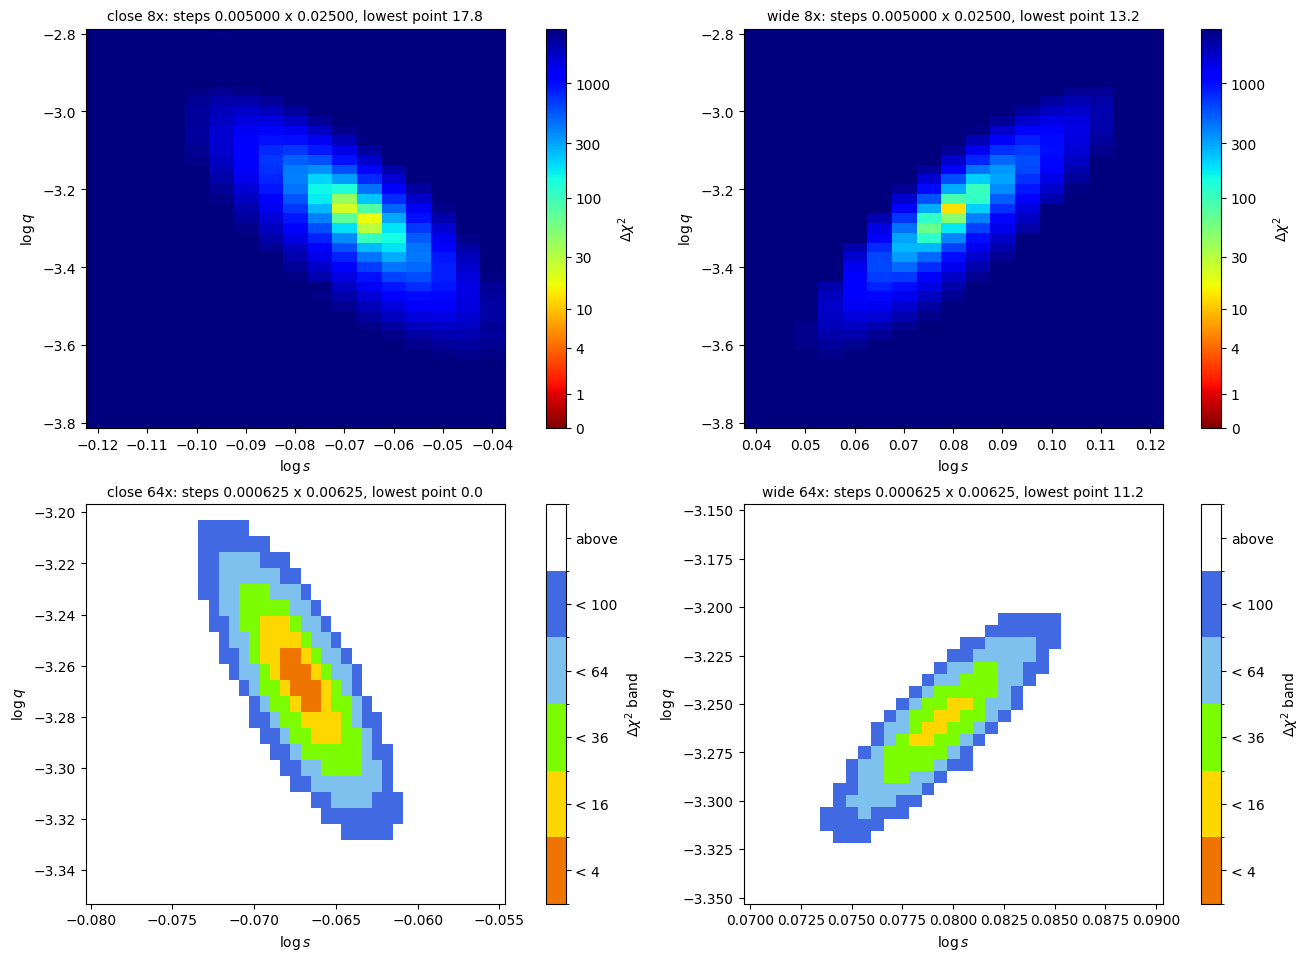

In [9]:
fig, axs = plt.subplots(2, 2, figsize=(13, 9.5), constrained_layout=True)
for ax, (name, m) in zip(axs.ravel(), MAPS[1:]):
    if name.endswith(" 64x"):
        figures.plot_map(m, bands=(4, 16, 36, 64, 100), ax=ax, chi2_ref=ref)
    else:
        figures.plot_map(m, ax=ax, vmax=3000, chi2_ref=ref)
    ax.set_title(f"{name}: steps {m['logs'][1] - m['logs'][0]:.6f} x {m['logq'][1] - m['logq'][0]:.5f}, "
                 f"lowest point {np.nanmin(m['chi2']) - ref:.1f}", fontsize=10)

Top: the 8× boxes on a log scale up to 3000; bottom: the 64× boxes with Δχ² bands 4, 16, 36, 64, 100. At 8× each
valley is a tilted streak whose lowest point is still 18 (close) and 13 (wide) above the best fit. The 64× boxes
resolve each into a single elongated minimum. The close one, at log *s* = −0.0669 and log *q* = −3.269, is the
global minimum; the wide one, at log *s* = +0.0794 and log *q* = −3.263, is 11 above it. Δχ² < 4 spans only about
±0.001 dex in log *s* and ±0.01 dex in log *q*. The two valleys are mirror images (*s* ↔ 1/*s*): along each,
*q* and the distance of the planet from the Einstein ring change together so that the central caustic keeps its
length.

## 7. The best fit

In [10]:
best_file = "data/rmdc0566_best.json"
if RECOMPUTE or not os.path.exists(best_file):
    log("polishing the two solutions")
    out = {}
    for name, m, extra in (("close", mapc64, best_first), ("wide", mapw64, wide_first)):
        i, j = np.unravel_index(np.nanargmin(m["chi2"]), m["chi2"].shape)
        x = m["pars"][i, j]
        starts = [np.array([x[0], x[1], x[2], m["logs"][i], m["logq"][j], x[3], x[4]]), extra]
        c_b, p_b = min((lenscape.fit_full(data, p, be, rounds=3, maxfev=6000) for p in starts), key=lambda r: r[0])
        c_s, p_s = lenscape.fit_full(season, p_b, be, rounds=2, maxfev=4000)
        out[name] = dict(p_binned=list(p_b), p_season=list(p_s))
    json.dump(dict(p_binned=out["close"]["p_binned"], p_season=out["close"]["p_season"], wide=out["wide"]),
              open(best_file, "w"), indent=1)
bj = json.load(open(best_file))
best, wide = np.array(bj["p_season"]), np.array(bj["wide"]["p_season"])
for name, p in (("close", best), ("wide", wide)):
    print(f"{name}: t0 = {p[0]:.4f}, u0 = {p[1]:+.5f}, tE = {p[2]:.3f} d, s = {10 ** p[3]:.5f}, q = {10 ** p[4]:.4e}, "
          f"alpha = {p[5] % (2 * np.pi):.4f}, rho = {10 ** p[6]:.3e}")
    print(f"       chi2 season {model.chi2(be, p, season):.1f} (N = {len(season)}), all {model.chi2(be, p, data_all):.1f} "
          f"(N = {len(data_all)})")
r = model.residuals(be, best, season)
for k, n in enumerate(season.names):
    print(f"  close, {n}: chi2 / N = {np.sum(r[season.idx == k] ** 2):.1f} / {np.sum(season.idx == k)}")
fs, fb = model.fluxes(model.magnification(be, best, season), season)
for k, n in enumerate(season.names):
    print(f"  {n}: source flux {fs[k]:8.4f} uJy ({mag(fs[k]) if fs[k] > 0 else np.nan:.2f} AB), "
          f"blend {fb[k]:8.4f} uJy ({mag(fb[k]) if fb[k] > 0 else np.nan:.2f} AB)")

close: t0 = 2950.4162, u0 = -0.02229, tE = 15.294 d, s = 0.85654, q = 5.4298e-04, alpha = 4.1365, rho = 9.156e-04
       chi2 season 8410.4 (N = 8096), all 49651.9 (N = 49488)
wide: t0 = 2950.4184, u0 = -0.02220, tE = 15.259 d, s = 1.20042, q = 5.4965e-04, alpha = 4.1381, rho = 9.164e-04
       chi2 season 8421.7 (N = 8096), all 49664.3 (N = 49488)
  close, F087: chi2 / N = 291.3 / 239
  close, F146: chi2 / N = 7890.7 / 7618
  close, F213: chi2 / N = 228.4 / 239
  F087: source flux   0.0286 uJy (27.76 AB), blend   0.1107 uJy (26.29 AB)
  F146: source flux   1.5314 uJy (23.44 AB), blend   5.0238 uJy (22.15 AB)
  F213: source flux   5.7050 uJy (22.01 AB), blend  78.9212 uJy (19.16 AB)


| parameter | close (best) | wide |
|---|---|---|
| *t*₀ (BJD′) | 2950.416 | 2950.418 |
| *u*₀ | −0.0223 | −0.0222 |
| *t*ₑ | 15.29 d | 15.26 d |
| *s* | 0.8565 | 1.2004 |
| *q* | 5.43 × 10⁻⁴ | 5.50 × 10⁻⁴ |
| α | 4.137 rad | 4.138 rad |
| ρ | 9.16 × 10⁻⁴ | 9.16 × 10⁻⁴ |
| χ² (all 49 488 points) | 49 651.9 | +12.4 |

χ²/N is 1.22, 1.04 and 0.96 in F087, F146 and F213 (season). The two solutions differ only in *s* (0.857 against
1.200 ≈ 1/0.833) and share all other parameters. The close one is preferred by Δχ² = 11–12 on the binned data,
the season and all six seasons alike: a mild preference, not a decisive one.

The source is 23.44 mag in F146 (AB), the blend 1.3 mag brighter (22.15). At a magnification of 43 the flux
rises by a factor of 11.

## 8. The light curve

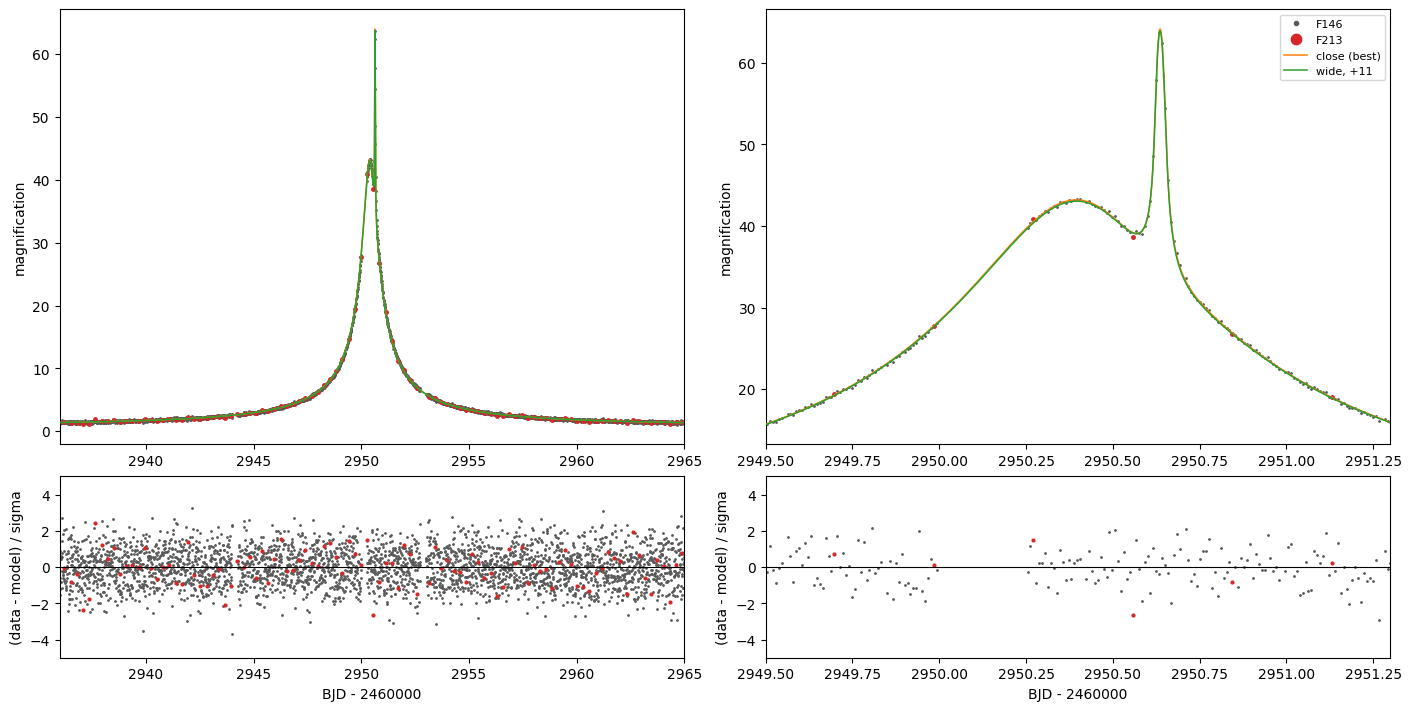

In [11]:
def plot_lc(sols, d=season, window=(2936, 2965), zoom=(2949.5, 2951.3)):
    # F146 and F213 as magnifications implied by each point (for the first solution); models; residuals of the first
    p = sols[0][1]
    fs, fb = model.fluxes(model.magnification(be, p, d), d)
    fig = plt.figure(figsize=(14, 7), constrained_layout=True)
    gs = fig.add_gridspec(2, 2, height_ratios=[2.4, 1])
    res = model.residuals(be, p, d)
    for col, (a, b) in enumerate((window, zoom)):
        ax, axr = fig.add_subplot(gs[0, col]), fig.add_subplot(gs[1, col])
        for k, (n, c) in enumerate(zip(d.names, ["C0", "0.35", "C3"])):
            if n == "F087":
                continue
            m = (d.idx == k) & (d.t > a) & (d.t < b)
            ax.plot(d.t[m], (d.f[m] - fb[k]) / fs[k], ".", ms=2 if n == "F146" else 5, color=c, label=n, zorder=2)
            axr.plot(d.t[m], res[m], ".", ms=2 if n == "F146" else 4, color=c)
        tt = np.linspace(a, b, 6000)
        for (lab, q), c in zip(sols, ("C1", "C2")):
            ax.plot(tt, be.lc(model.clamp(q)[0], tt), color=c, lw=1.1, label=lab, zorder=3)
        ax.set_xlim(a, b); ax.set_ylabel("magnification")
        axr.axhline(0, color="k", lw=0.8); axr.set_xlim(a, b); axr.set_ylim(-5, 5)
        axr.set_ylabel("(data - model) / sigma"); axr.set_xlabel("BJD - 2460000")
    ax.legend(fontsize=8, markerscale=3)
    return fig

plot_lc([("close (best)", best), (f"wide, +{model.chi2(be, wide, season) - model.chi2(be, best, season):.0f}", wide)]);

Drawn as magnification (each point's flux with the fitted blend removed, divided by the source flux). Left: the
event, a high-magnification peak with *t*ₑ = 15 d. Right: the peak. The magnification rises smoothly to a broad
maximum of 43 at BJD′ 2950.40, dips to 39 at 2950.56 and shoots up to a spike of 64 at 2950.63, then falls
smoothly. The residuals are flat. The wide solution (green) is indistinguishable at this scale.

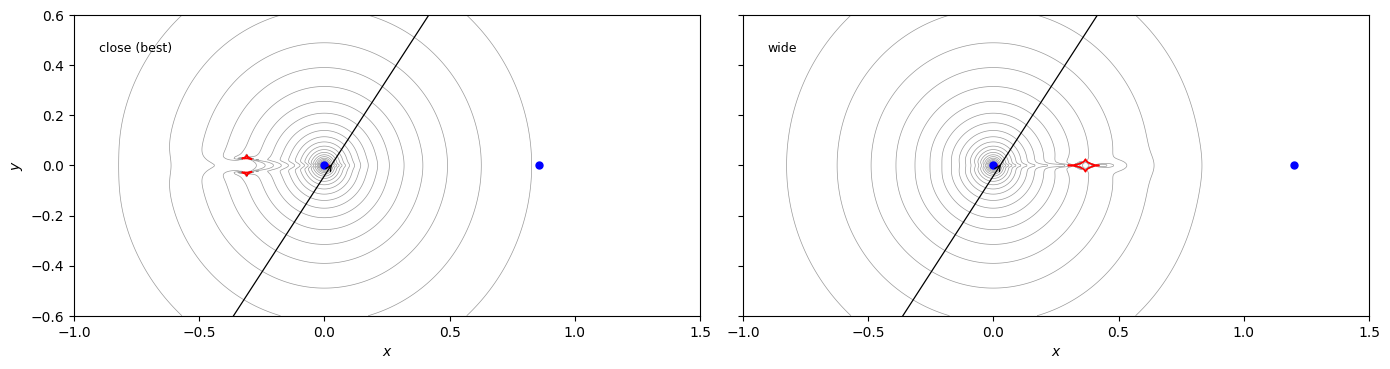

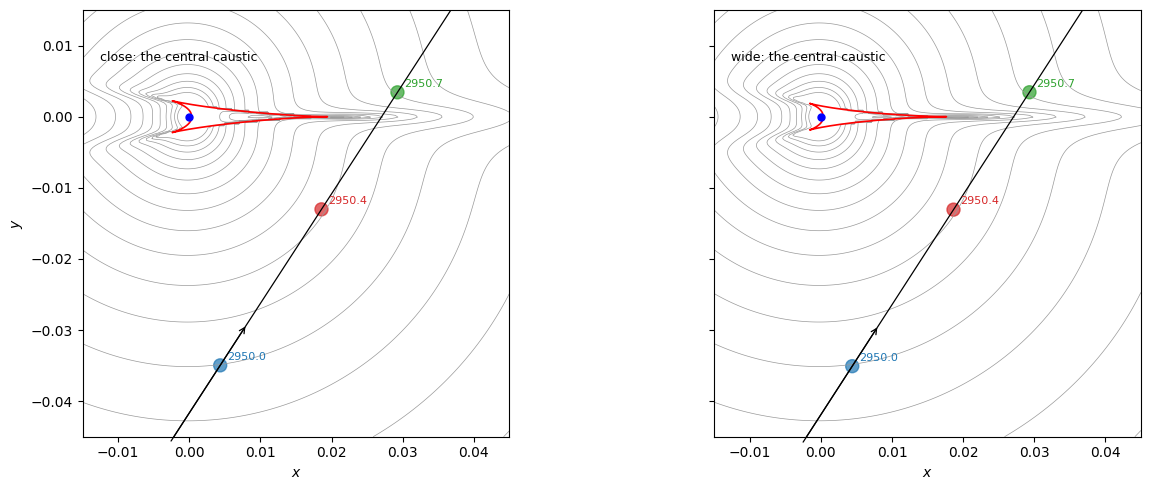

In [12]:
x0 = caustics.lens_positions(10 ** best[3], 10 ** best[4])[0]
fig = figures.plot_geometry([best, wide], labels=["close (best)", "wide"], ncols=2, figsize=(14, 4.6),
                            extent=(-1.0, 1.5, -0.6, 0.6))
fig = figures.plot_geometry([best, wide], labels=["close: the central caustic", "wide: the central caustic"], ncols=2,
                            figsize=(14, 5), extent=(-0.015, 0.045, -0.045, 0.015), t_arrow=2949.8)
for ax, p in zip(fig.axes, (best, wide)):
    x0 = caustics.lens_positions(10 ** p[3], 10 ** p[4])[0]
    for t, c in ((2950.0, "C0"), (2950.4, "C3"), (2950.7, "C2")):
        z = caustics.trajectory(p, [t])[0]
        ax.add_patch(plt.Circle((z.real - x0, z.imag), 10 ** p[6], color=c, alpha=0.7))
        ax.annotate(f"{t:.1f}", (z.real - x0, z.imag), xytext=(5, 4), textcoords="offset points", fontsize=8, color=c)

Top: the whole system. In the close solution (left) the planet is at 0.86 Einstein radii from the host (origin)
and its two small triangular planetary caustics lie on the other side of the host, at *x* ≈ −0.3; in the wide
solution (right) the planet is at 1.20 and its planetary caustic at *x* ≈ 0.37. The source passes close to the
host and far from both planetary caustics.

Bottom: the central caustic, a thin arrowhead 0.022 Einstein radii long and 0.004 wide, pointing towards the
planet. The source (discs: its size at three times) crosses the planet–host axis just beyond the tip. The hump at
BJD′ 2950.4 is the ordinary high magnification near the host, with a slight boost from the caustic; the spike at
2950.63 comes when the source passes the **front cusp** at about 7 source radii. The source never crosses the
caustic, and the spike's shape constrains ρ only weakly. The close and wide caustics are nearly identical, which
is why the two solutions are so close in χ².

## 9. What kind of system is this?

**Measured.** A planet with *q* = 5.4 × 10⁻⁴ of its host's mass (about half the Jupiter–Sun ratio) at
*s* = 0.857 Einstein radii (or 1.200, less favoured by Δχ² = 12). *t*ₑ = 15.3 d, and the source takes
ρ *t*ₑ = 20 minutes to cross its radius.

**Physical scale (rough).** The fit gives the source 23.44 mag in F146 (AB). With the challenge's extinction
(2.65 mag) and a source at 8 kpc, its absolute F146 magnitude is 6.3, about 1.6 magnitudes fainter than the Sun in
the near infrared (*H*_AB ≈ 4.7). With the Sun's surface brightness that is about 0.5 solar radii (a K or M dwarf;
only an order of magnitude), and θ⋆ ≈ 0.28 µas. With ρ that gives θₑ ≈ 0.31 mas and a relative proper motion
μ ≈ 7 mas/yr.

In [13]:
A146 = 2.65                                    # extinction in F146 from the challenge's photometry table
M146 = mag(fs[1]) - A146 - 5 * np.log10(8000 / 10)                # source at 8 kpc
theta_s = 0.581e-3 * 10 ** (-(M146 - 4.71) / 5)                   # mas; 0.581 micro-arcsec = 1 R_sun at 8 kpc
theta_E = theta_s / 10 ** best[6]
DS = 8.0
print(f"M_F146 = {M146:.2f}, R ~ {10 ** (-(M146 - 4.71) / 5):.2f} R_sun, theta_* = {theta_s * 1e3:.3f} micro-arcsec, "
      f"theta_E = {theta_E:.4f} mas, mu_rel = {theta_E / best[2] * 365.25:.1f} mas/yr")
print(f"{'D_L (kpc)':>9s} {'M_host (M_sun)':>14s} {'M_planet (MJup)':>15s} {'a_perp (AU)':>11s}")
for DL in (3.0, 5.0, 6.0, 7.0, 7.5):
    M = theta_E ** 2 / (8.144 * (1 / DL - 1 / DS))
    print(f"{DL:9.1f} {M:14.3f} {10 ** best[4] * M * 1047.6:15.2f} {10 ** best[3] * theta_E * DL:11.2f}")

M_F146 = 6.27, R ~ 0.49 R_sun, theta_* = 0.283 micro-arcsec, theta_E = 0.3091 mas, mu_rel = 7.4 mas/yr
D_L (kpc) M_host (M_sun) M_planet (MJup) a_perp (AU)
      3.0          0.056            0.03        0.79
      5.0          0.156            0.09        1.32
      6.0          0.282            0.16        1.59
      7.0          0.657            0.37        1.85
      7.5          1.408            0.80        1.99


θₑ ≈ 0.3 mas is three times that of RMDC26_000209. For a lens at 5–7 kpc the host has 0.16–0.66 solar masses
(an M or K dwarf) and the planet 0.09–0.37 Jupiter masses (a Saturn-like planet) at a projected 1.3–1.9 AU. A
lens nearer than about 4 kpc would need a host below 0.1 solar masses, and one beyond 7.5 kpc a host above the
mass of the Sun; neither is excluded, but the middle of the range is more likely. The usual caveats apply: θ⋆
rests on one filter, the Sun's surface brightness and an assumed source distance; ρ is only weakly measured
here, and parallax is not fitted.

## 10. Summary

* A high-magnification event (magnification 43) with a spike to 64 six hours after the peak: the source passes
  the front cusp of the **central caustic**.
* The angle-screen guided fits find both the close and the wide solution at once; everything else is worse by
  35 000 or more.
* The coarse map shows the V of central-caustic events with two thin columns; the valleys are about 0.002 dex
  wide in log *s*, and only **64× zooms** resolve them (the 8× boxes still miss them by 13–18).
* Close solution *s* = 0.857, *q* = 5.4 × 10⁻⁴, preferred by Δχ² = 12 over the wide one (*s* = 1.200);
  χ²/N = 1.00 on all 49 488 points.
* A rough scale suggests a Saturn-mass planet around an M or K dwarf at 1.3–1.9 AU.
* Not done: parallax, MCMC uncertainties, limb darkening, a proper physical analysis.

**References.** Dominik, M. 1999, A&A, 349, 108. Griest, K., & Safizadeh, N. 1998, ApJ, 500, 37. Penny, M. T., et
al. 2019, ApJS, 241, 3. Roman Microlensing Data Challenge 2026, RGES-PIT,
[rges-pit.org/data-challenge](https://rges-pit.org/data-challenge/).